# Question 2 — South African Inflation Forecasting

## Lwazi Nhlapo
## Fumane Malangabe

## Objective

This notebook develops monthly forecasting models for the South African headline Consumer Price Index (CPI).

The analysis compares:

1. **ARIMA/SARIMA** as the statistical time-series model;
2. **Support Vector Regression (SVR) with an RBF kernel**, with Bayesian hyperparameter optimisation using Optuna; and
3. **Random Forest Regressor** as an additional nonlinear machine-learning benchmark.

All model selection and hyperparameter tuning use historical observations only. Forecast performance is evaluated using expanding-window / rolling-origin backtesting. The preferred model is then refitted using all information available through December 2025 to produce monthly forecasts for January–December 2026.

## 1. Forecast target and data

The forecasting target is the **South African headline CPI index**.

The CPI index is modelled directly because it is the official monthly price-level series published by Statistics South Africa and supports a direct January–December 2026 forecast of the price level. Year-to-year inflation is subsequently derived from the forecast CPI index:

$$
\widehat{\pi}^{YoY}_t
=
100\left(
\frac{\widehat{CPI}_t}{CPI_{t-12}}-1
\right)
$$

The modelling history begins in January 2015 to provide sufficient observations for lagged, rolling and seasonal features. The full January 2021–December 2025 period required by the assignment is included, while the earlier observations provide additional historical estimation information. No 2026 observations are used for training, tuning, model selection or backtesting.

In [5]:
# ============================================================
# SETUP AND REPRODUCIBILITY
# ============================================================

import sys
import subprocess
import warnings
import itertools
import time
from pathlib import Path

warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Optuna is used for Bayesian / sequential model-based optimisation of SVR.
try:
    import optuna
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "optuna"])
    import optuna

optuna.logging.set_verbosity(optuna.logging.WARNING)

# Ensure Excel export support is available in Colab.
try:
    import openpyxl
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "openpyxl"])
    import openpyxl


SEED = 42
np.random.seed(SEED)

pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

In [6]:



# ------------------------------------------------------------
# 1. Folder containing the datasets
# ------------------------------------------------------------

DATA_DIR = Path(
    "/Users/lwazinhlapo/Documents/"
    "Business Analytics/"
    "EDAB Assignment 2/"
    "Data Set"
)

if not DATA_DIR.exists():
    raise FileNotFoundError(
        f"Dataset folder could not be found:\n{DATA_DIR}"
    )

if not DATA_DIR.is_dir():
    raise ValueError(
        f"DATA_DIR should be a folder:\n{DATA_DIR}"
    )


# ------------------------------------------------------------
# 2. Find the actual CPI Excel FILE inside the folder
# ------------------------------------------------------------

CPI_FILENAME = (
    "Excel - CPI (COICOP) from January 2008 (202605).xlsx"
)

exact_file = DATA_DIR / CPI_FILENAME


# First try the exact filename
if exact_file.exists() and exact_file.is_file():
    CPI_FILE = exact_file

else:
    # Otherwise search through the folder and subfolders
    possible_files = [
        file
        for file in DATA_DIR.rglob("*.xlsx")
        if (
            file.is_file()
            and "CPI" in file.name.upper()
        )
    ]

    if len(possible_files) == 0:
        raise FileNotFoundError(
            "No CPI .xlsx file was found inside:\n"
            f"{DATA_DIR}"
        )

    print("Possible CPI Excel files found:")

    for i, file in enumerate(possible_files, start=1):
        print(f"{i}. {file}")

    # Prefer the intended Stats SA file
    preferred_files = [
        file
        for file in possible_files
        if (
            "COICOP" in file.name.upper()
            and "202605" in file.name
        )
    ]

    if preferred_files:
        CPI_FILE = preferred_files[0]
    else:
        CPI_FILE = possible_files[0]


# ------------------------------------------------------------
# 3. Confirm that CPI_FILE is really a file
# ------------------------------------------------------------

if CPI_FILE.is_dir():
    raise ValueError(
        f"The selected CPI path is a folder, not an Excel file:\n"
        f"{CPI_FILE}"
    )

if not CPI_FILE.is_file():
    raise FileNotFoundError(
        f"The CPI Excel file could not be found:\n"
        f"{CPI_FILE}"
    )


print("=" * 70)
print("CPI FILE CHECK")
print("=" * 70)

print("Dataset folder:")
print(DATA_DIR)

print("\nExcel file selected:")
print(CPI_FILE)

print("\nIs folder:", CPI_FILE.is_dir())
print("Is file:", CPI_FILE.is_file())

print(
    "File size:",
    f"{CPI_FILE.stat().st_size:,} bytes"
)

print("=" * 70)


# ------------------------------------------------------------
# 4. Load the Stats SA Excel workbook
# ------------------------------------------------------------

EXPECTED_SHEET = "Excel table from 2008"

excel_file = pd.ExcelFile(
    CPI_FILE,
    engine="openpyxl"
)

print("\nAvailable sheets:")
print(excel_file.sheet_names)


if EXPECTED_SHEET not in excel_file.sheet_names:
    raise ValueError(
        f"Expected sheet '{EXPECTED_SHEET}' was not found.\n"
        f"Available sheets: {excel_file.sheet_names}"
    )


df = pd.read_excel(
    CPI_FILE,
    sheet_name=EXPECTED_SHEET,
    engine="openpyxl",
)


# Clean column names
df.columns = [
    str(col).strip()
    for col in df.columns
]


# ------------------------------------------------------------
# 5. Select the EXACT official CPI headline index
# ------------------------------------------------------------

target_row = df.loc[
    (df["H03"] == "CPS00000")
    & (df["H04"] == "CPI Headline")
    & (df["H13"] == "All urban areas")
    & (df["H17"] == "Index")
]

if len(target_row) != 1:
    raise ValueError(
        "Headline CPI row could not be uniquely identified."
    )

target_row = target_row.iloc[0]


print("\nOfficial target successfully identified:")

print("H03:", target_row["H03"])
print("H04:", target_row["H04"])
print("H13:", target_row["H13"])
print("H17:", target_row["H17"])


# ------------------------------------------------------------
# 6. Identify Stats SA monthly columns
# ------------------------------------------------------------

def month_cols(df):
    return [
        c
        for c in df.columns
        if (
            isinstance(c, str)
            and c.startswith("MO")
            and len(c) == 8
            and c[2:].isdigit()
        )
    ]


mcols = month_cols(df)

if len(mcols) == 0:
    raise ValueError(
        "No monthly Stats SA columns were found."
    )


# ------------------------------------------------------------
# 7. Convert monthly columns to dates
#
# Example:
# MO012021 -> 2021-01-01
# ------------------------------------------------------------

dates = pd.to_datetime(
    [
        f"{c[4:8]}-{c[2:4]}-01"
        for c in mcols
    ],
    format="%Y-%m-%d",
)


# ------------------------------------------------------------
# 8. Extract CPI values
# ------------------------------------------------------------

values = pd.to_numeric(
    target_row[mcols],
    errors="coerce"
).to_numpy()


cpi_index_full = pd.Series(
    values,
    index=dates,
    name="CPI_Index",
    dtype=float,
).sort_index()


# ------------------------------------------------------------
# 9. Define modelling period
# ------------------------------------------------------------

MODEL_START = pd.Timestamp("2015-01-01")
CUTOFF = pd.Timestamp("2025-12-01")


train_cpi = (
    cpi_index_full
    .loc[MODEL_START:CUTOFF]
    .asfreq("MS")
    .astype(float)
)


# ------------------------------------------------------------
# 10. Data-quality validation
# ------------------------------------------------------------

expected_dates = pd.date_range(
    MODEL_START,
    CUTOFF,
    freq="MS"
)


if train_cpi.empty:
    raise ValueError(
        "The modelling dataset is empty."
    )


if len(train_cpi) != len(expected_dates):
    raise ValueError(
        f"Expected {len(expected_dates)} monthly observations "
        f"but found {len(train_cpi)}."
    )


if train_cpi.isna().any():
    raise ValueError(
        "Missing CPI observations detected:\n"
        f"{train_cpi[train_cpi.isna()].index.tolist()}"
    )


if train_cpi.index.duplicated().any():
    raise ValueError(
        "Duplicate monthly dates were detected."
    )


# ------------------------------------------------------------
# 11. Verify official headline CPI values
# ------------------------------------------------------------

assert np.isclose(
    train_cpi.loc["2021-01-01"],
    81.7
), (
    "January 2021 does not match "
    "the official headline CPI series."
)


assert np.isclose(
    train_cpi.loc["2025-12-01"],
    103.6
), (
    "December 2025 does not match "
    "the official headline CPI series."
)


# ------------------------------------------------------------
# 12. Final output
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("OFFICIAL STATSA HEADLINE CPI DATA")
print("=" * 70)

print(
    "Series: CPI Headline | All urban areas | Index"
)

print(
    f"Period: "
    f"{train_cpi.index.min().date()} "
    f"to "
    f"{train_cpi.index.max().date()}"
)

print(
    f"Observations: {len(train_cpi)}"
)

print(
    f"Missing values: {train_cpi.isna().sum()}"
)

print(
    f"Duplicate dates: "
    f"{train_cpi.index.duplicated().sum()}"
)

print(
    f"January 2021 CPI: "
    f"{train_cpi.loc['2021-01-01']:.1f}"
)

print(
    f"December 2025 CPI: "
    f"{train_cpi.loc['2025-12-01']:.1f}"
)

print("=" * 70)


display(
    train_cpi
    .tail(12)
    .to_frame(
        name="Headline_CPI_Index"
    )
)

CPI FILE CHECK
Dataset folder:
/Users/lwazinhlapo/Documents/Business Analytics/EDAB Assignment 2/Data Set

Excel file selected:
/Users/lwazinhlapo/Documents/Business Analytics/EDAB Assignment 2/Data Set/Excel - CPI (COICOP) from January 2008 (202605).xlsx

Is folder: False
Is file: True
File size: 898,352 bytes

Available sheets:
['Excel table from 2008']

Official target successfully identified:
H03: CPS00000
H04: CPI Headline
H13: All urban areas
H17: Index

OFFICIAL STATSA HEADLINE CPI DATA
Series: CPI Headline | All urban areas | Index
Period: 2015-01-01 to 2025-12-01
Observations: 132
Missing values: 0
Duplicate dates: 0
January 2021 CPI: 81.7
December 2025 CPI: 103.6


,Headline_CPI_Index
2025-01-01,100.3000
2025-02-01,101.2000
2025-03-01,101.6000
2025-04-01,101.9000
2025-05-01,102.1000
2025-06-01,102.4000
2025-07-01,103.3000
2025-08-01,103.2000
2025-09-01,103.4000
2025-10-01,103.5000


## 2. Exploratory time-series analysis and transformations

The exploratory analysis evaluates the CPI series for trend, seasonality, distribution, persistence and stationarity before model estimation.

The CPI index is strongly trending, so the logarithm of CPI and its first difference are also examined:

$$
\Delta \log(CPI_t)
=
\log(CPI_t)-\log(CPI_{t-1})
$$

For relatively small changes, \(100\Delta\log(CPI_t)\) approximates the monthly percentage change in the price level. This transformation is useful because it converts the trending price index into a more stable change series.

The statistical model candidates therefore include first differencing, while the machine-learning models forecast the next monthly log change and then reconstruct the CPI index level.

,Diagnostic,Result
0,Number of observations,132
1,Duplicate dates,0
2,Expected monthly dates,132
3,Missing monthly dates,0
4,Missing CPI values,0


,Series,Observations,Mean,Median,Std_Dev,Minimum,Maximum
0,CPI index,132,82.4235,80.4500,12.4209,61.7000,103.6000
1,Monthly log change (%),131,0.3956,0.2996,0.3871,-0.7547,1.4412


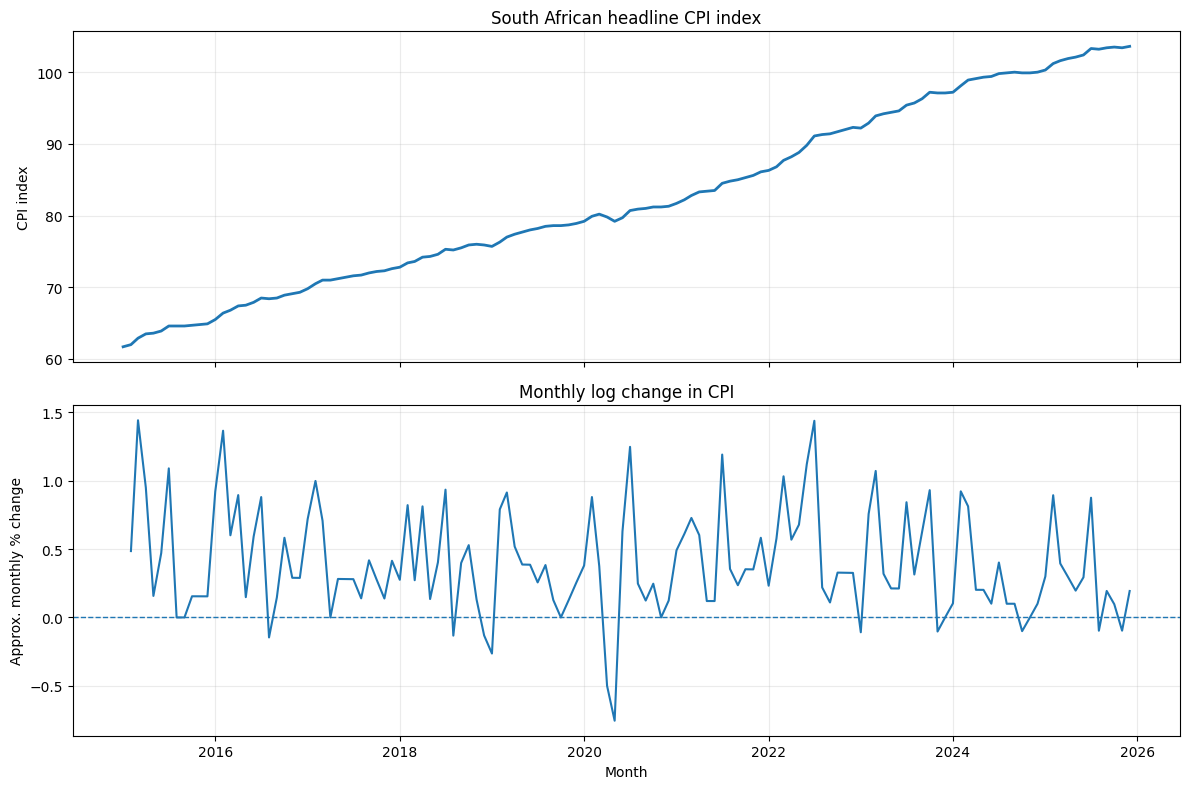

,mean,median,std,min,max,count
Jan,0.3047,0.2873,0.3546,-0.2639,0.9203,10
Feb,0.8270,0.8208,0.2381,0.4850,1.3647,11
Mar,0.7586,0.7273,0.3478,0.2721,1.4412,11
Apr,0.4236,0.5181,0.4266,-0.5000,0.9494,11
May,0.1601,0.1961,0.3434,-0.7547,0.6780,11
Jun,0.4186,0.3854,0.2894,0.1007,1.1198,11
Jul,0.8575,0.8798,0.3953,0.2561,1.4373,11
Aug,0.1256,0.1396,0.1961,-0.1461,0.3829,11
Sep,0.2251,0.1461,0.1827,0.0000,0.6250,11
Oct,0.3087,0.2774,0.2911,-0.1001,0.9302,11


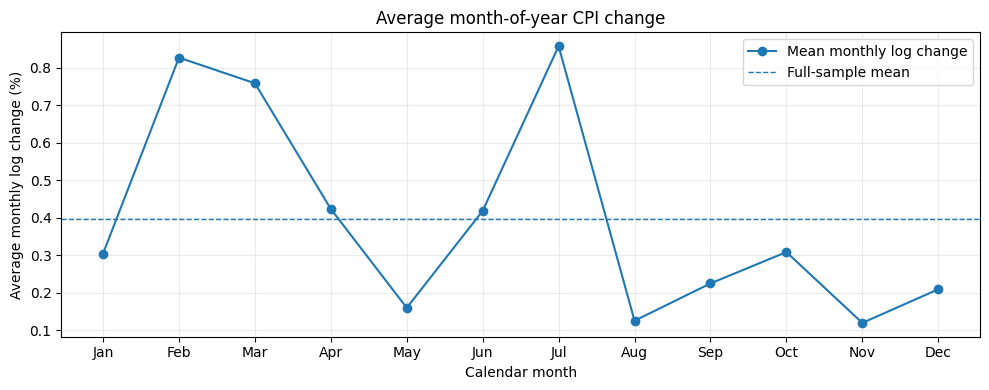

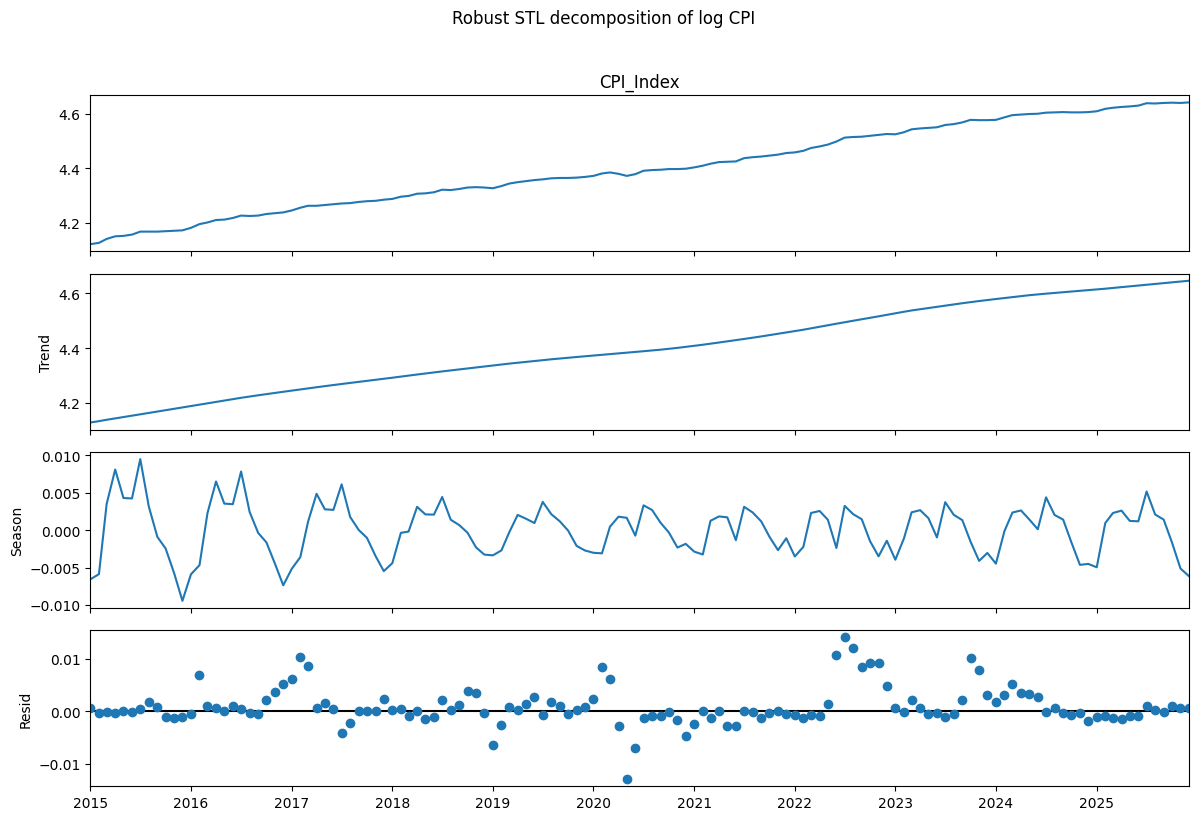

Estimated trend strength: 0.999
Estimated seasonal strength: 0.394


,Series,Observations,ADF_Statistic,ADF_p_value,KPSS_Statistic,KPSS_p_value
0,log(CPI) level,132,-0.8136,0.8151,1.9769,0.0100
1,First difference of log(CPI),131,-1.8986,0.3327,0.2155,0.1000


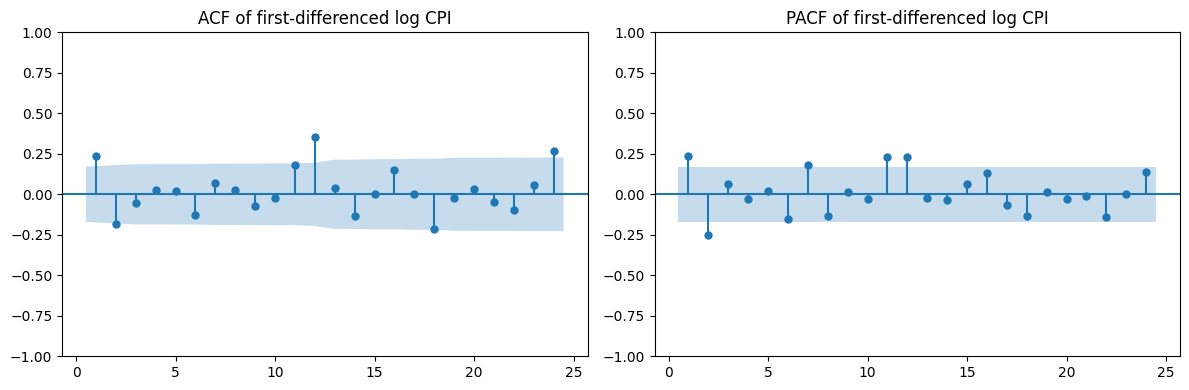

In [7]:
# ============================================================
# EXPLORATORY TIME-SERIES ANALYSIS
# ============================================================

log_cpi = np.log(train_cpi)
dlog_cpi = log_cpi.diff()
monthly_log_change_pct = 100 * dlog_cpi

# ------------------------------------------------------------
# Temporal and data-quality audit
# ------------------------------------------------------------

expected_dates = pd.date_range(
    train_cpi.index.min(),
    train_cpi.index.max(),
    freq="MS"
)

data_audit = pd.DataFrame({
    "Diagnostic": [
        "Number of observations",
        "Duplicate dates",
        "Expected monthly dates",
        "Missing monthly dates",
        "Missing CPI values",
    ],
    "Result": [
        len(train_cpi),
        int(train_cpi.index.duplicated().sum()),
        len(expected_dates),
        len(expected_dates.difference(train_cpi.index)),
        int(train_cpi.isna().sum()),
    ],
})

display(data_audit)

# ------------------------------------------------------------
# Descriptive statistics
# ------------------------------------------------------------

descriptive_statistics = pd.DataFrame({
    "Series": ["CPI index", "Monthly log change (%)"],
    "Observations": [
        train_cpi.count(),
        monthly_log_change_pct.count(),
    ],
    "Mean": [
        train_cpi.mean(),
        monthly_log_change_pct.mean(),
    ],
    "Median": [
        train_cpi.median(),
        monthly_log_change_pct.median(),
    ],
    "Std_Dev": [
        train_cpi.std(),
        monthly_log_change_pct.std(),
    ],
    "Minimum": [
        train_cpi.min(),
        monthly_log_change_pct.min(),
    ],
    "Maximum": [
        train_cpi.max(),
        monthly_log_change_pct.max(),
    ],
})

display(descriptive_statistics.round(4))

# ------------------------------------------------------------
# Trend and transformed series
# ------------------------------------------------------------

fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

axes[0].plot(
    train_cpi.index,
    train_cpi.values,
    linewidth=2
)
axes[0].set_title("South African headline CPI index")
axes[0].set_ylabel("CPI index")
axes[0].grid(alpha=0.25)

axes[1].plot(
    monthly_log_change_pct.index,
    monthly_log_change_pct.values,
    linewidth=1.5
)
axes[1].axhline(
    0,
    linestyle="--",
    linewidth=1
)
axes[1].set_title("Monthly log change in CPI")
axes[1].set_ylabel("Approx. monthly % change")
axes[1].set_xlabel("Month")
axes[1].grid(alpha=0.25)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# Month-of-year seasonality
# ------------------------------------------------------------

seasonal_profile = pd.DataFrame({
    "Month": train_cpi.index.month,
    "Monthly_Log_Change_pct": monthly_log_change_pct.values,
}).dropna()

month_names = [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
]

monthly_seasonality = (
    seasonal_profile
    .groupby("Month")["Monthly_Log_Change_pct"]
    .agg(["mean", "median", "std", "min", "max", "count"])
    .reindex(range(1, 13))
)

monthly_seasonality.index = month_names

display(monthly_seasonality.round(4))

plt.figure(figsize=(10, 4))
plt.plot(
    month_names,
    monthly_seasonality["mean"],
    marker="o",
    label="Mean monthly log change"
)
plt.axhline(
    monthly_log_change_pct.mean(),
    linestyle="--",
    linewidth=1,
    label="Full-sample mean"
)
plt.title("Average month-of-year CPI change")
plt.xlabel("Calendar month")
plt.ylabel("Average monthly log change (%)")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# Robust STL decomposition
# ------------------------------------------------------------

stl_result = STL(
    log_cpi,
    period=12,
    robust=True
).fit()

fig = stl_result.plot()
fig.set_size_inches(12, 8)
plt.suptitle("Robust STL decomposition of log CPI", y=1.02)
plt.tight_layout()
plt.show()

def component_strength(component, remainder):
    numerator = np.var(remainder)
    denominator = np.var(component + remainder)

    if denominator <= 0:
        return np.nan

    return max(0, 1 - numerator / denominator)

trend_strength = component_strength(
    stl_result.trend,
    stl_result.resid
)

seasonal_strength = component_strength(
    stl_result.seasonal,
    stl_result.resid
)

print(f"Estimated trend strength: {trend_strength:.3f}")
print(f"Estimated seasonal strength: {seasonal_strength:.3f}")

# ------------------------------------------------------------
# ADF and KPSS stationarity tests
# ------------------------------------------------------------

def stationarity_row(series, name):
    s = pd.Series(series).dropna().astype(float)

    adf_result = adfuller(
        s,
        autolag="AIC"
    )

    try:
        kpss_result = kpss(
            s,
            regression="c",
            nlags="auto"
        )

        kpss_statistic = kpss_result[0]
        kpss_p_value = kpss_result[1]

    except Exception:
        kpss_statistic = np.nan
        kpss_p_value = np.nan

    return {
        "Series": name,
        "Observations": len(s),
        "ADF_Statistic": adf_result[0],
        "ADF_p_value": adf_result[1],
        "KPSS_Statistic": kpss_statistic,
        "KPSS_p_value": kpss_p_value,
    }

stationarity = pd.DataFrame([
    stationarity_row(
        log_cpi,
        "log(CPI) level"
    ),
    stationarity_row(
        dlog_cpi,
        "First difference of log(CPI)"
    ),
])

display(stationarity.round(4))

# ------------------------------------------------------------
# ACF and PACF
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1,
    2,
    figsize=(12, 4)
)

plot_acf(
    dlog_cpi.dropna(),
    lags=24,
    zero=False,
    ax=axes[0]
)
axes[0].set_title(
    "ACF of first-differenced log CPI"
)

plot_pacf(
    dlog_cpi.dropna(),
    lags=24,
    zero=False,
    method="ywm",
    ax=axes[1]
)
axes[1].set_title(
    "PACF of first-differenced log CPI"
)

plt.tight_layout()
plt.show()

### Exploratory interpretation

The CPI index displays a persistent upward trend, so modelling the untransformed level alone may primarily capture the long-run rise in prices rather than short-run inflation dynamics.

The first difference of log CPI is substantially more stable and is therefore appropriate for ARIMA/SARIMA specifications with \(d=1\) and for the machine-learning target. The ADF and KPSS tests, ACF/PACF plots, month-of-year profile and STL decomposition are interpreted jointly rather than relying on one diagnostic in isolation.

Seasonality is tested empirically rather than imposed automatically. Seasonal ARIMA terms are retained only when they improve historical forecast performance.

## 3. Expanding-window / rolling-origin backtesting design

Two time-aware evaluation designs are used.

### 3.1 One-month-ahead rolling-origin evaluation

The one-step evaluation measures repeated forecasts of the next monthly CPI index.

- **Hyperparameter tuning origins:** January 2019–October 2021 (quarterly forecast origins)
- **Evaluation origins:** December 2021–November 2025

At forecast origin \(t\), each model uses only information available up to that date to predict \(t+1\).

### 3.2 Multi-horizon backtest

The assignment requires twelve monthly forecasts for 2026 from information available through December 2025. A second backtest uses quarterly historical forecast origins and evaluates horizons \(h=1,\ldots,12\) from historical forecast origins.

The multi-horizon test is more demanding because forecast uncertainty accumulates with the horizon.

No random train/test split is used.

In [8]:
# ============================================================
# BACKTEST WINDOWS AND METRICS
# ============================================================

TUNE_ORIGINS = pd.date_range("2019-01-01", "2021-10-01", freq="3MS")
EVAL_ORIGINS = pd.date_range("2021-12-01", "2025-11-01", freq="MS")

MULTI_ORIGINS = pd.date_range("2022-01-01", "2024-10-01", freq="3MS")
H = 12

MASE_SCALE = train_cpi.loc[:"2021-11-01"].diff().abs().dropna().mean()

def smape(y_true, y_pred):
    y_true = np.asarray(y_true, float)
    y_pred = np.asarray(y_pred, float)
    den = np.abs(y_true) + np.abs(y_pred)
    mask = den > 0
    return 100*np.mean(2*np.abs(y_true[mask]-y_pred[mask])/den[mask])

def metrics_table(y_true, y_pred, model_name):
    y_true = np.asarray(y_true, float)
    y_pred = np.asarray(y_pred, float)
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mape = 100*np.mean(np.abs((y_true-y_pred)/y_true))
    return {
        "Model": model_name,
        "MAE": mae,
        "RMSE": rmse,
        "MAPE_pct": mape,
        "sMAPE_pct": smape(y_true, y_pred),
        "MASE": mae / MASE_SCALE,
        "MAE_below_0.5": mae < 0.5,
        "RMSE_below_1": rmse < 1.0,
    }

## 4. ARIMA/SARIMA model development

ARIMA and SARIMA are appropriate because CPI is a monthly time series with a non-stationary level and serial dependence.

Candidate specifications are fitted to log CPI and include first differencing. Both non-seasonal ARIMA and seasonal SARIMA structures are tested. Model order is selected using expanding-window forecast accuracy on the historical tuning period only.

The statistical model is therefore selected for out-of-sample forecasting performance rather than solely for in-sample information criteria.

In [9]:
# ============================================================
# ARIMA / SARIMA MODEL SELECTION
# ============================================================

ARIMA_SARIMA_CANDIDATES = [
    ((1,1,0), (0,0,0,12)),
    ((0,1,1), (0,0,0,12)),
    ((1,1,1), (0,0,0,12)),
    ((1,1,2), (0,0,0,12)),
    ((1,1,1), (1,0,0,12)),
    ((1,1,2), (1,0,1,12)),
]

def fit_arima_sarima(
    history,
    order,
    seasonal_order
):
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")

        return SARIMAX(
            np.log(history),
            order=order,
            seasonal_order=seasonal_order,
            trend="c",
            enforce_stationarity=False,
            enforce_invertibility=False,
        ).fit(
            disp=False,
            maxiter=150
        )

def arima_sarima_one_step_predictions(
    origins,
    order,
    seasonal_order
):
    rows = []

    for origin in origins:
        history = train_cpi.loc[:origin]

        fitted_model = fit_arima_sarima(
            history,
            order,
            seasonal_order
        )

        forecast_value = float(
            np.exp(
                fitted_model.forecast(1).iloc[0]
            )
        )

        target_month = (
            origin
            + pd.DateOffset(months=1)
        )

        rows.append({
            "origin": origin,
            "target_month": target_month,
            "actual": float(
                train_cpi.loc[target_month]
            ),
            "forecast": forecast_value,
        })

    return pd.DataFrame(rows)

arima_sarima_tuning_rows = []

for order, seasonal_order in ARIMA_SARIMA_CANDIDATES:

    try:
        predictions = (
            arima_sarima_one_step_predictions(
                TUNE_ORIGINS,
                order,
                seasonal_order
            )
        )

        arima_sarima_tuning_rows.append({
            "Order": order,
            "Seasonal_Order": seasonal_order,
            "MAE": mean_absolute_error(
                predictions["actual"],
                predictions["forecast"]
            ),
            "RMSE": np.sqrt(
                mean_squared_error(
                    predictions["actual"],
                    predictions["forecast"]
                )
            ),
            "Status": "Successful",
        })

    except Exception as error:
        arima_sarima_tuning_rows.append({
            "Order": order,
            "Seasonal_Order": seasonal_order,
            "MAE": np.nan,
            "RMSE": np.nan,
            "Status": f"Failed: {error}",
        })

arima_sarima_tuning = (
    pd.DataFrame(
        arima_sarima_tuning_rows
    )
    .sort_values(
        ["MAE", "RMSE"],
        na_position="last"
    )
    .reset_index(drop=True)
)

display(
    arima_sarima_tuning.round(4)
)

successful_statistical_models = (
    arima_sarima_tuning.loc[
        arima_sarima_tuning["Status"]
        .eq("Successful")
    ]
    .copy()
)

BEST_ARIMA_ORDER = tuple(
    successful_statistical_models
    .iloc[0]["Order"]
)

BEST_SEASONAL_ORDER = tuple(
    successful_statistical_models
    .iloc[0]["Seasonal_Order"]
)

def statistical_model_name(
    order,
    seasonal_order
):
    if seasonal_order[:3] != (0, 0, 0):
        return (
            f"SARIMA{order}×"
            f"{seasonal_order[:3]}_{seasonal_order[3]}"
        )

    return f"ARIMA{order}"

STATISTICAL_MODEL_NAME = (
    statistical_model_name(
        BEST_ARIMA_ORDER,
        BEST_SEASONAL_ORDER
    )
)

print(
    "Selected statistical model:",
    STATISTICAL_MODEL_NAME
)
print(
    "Tuning MAE:",
    round(
        successful_statistical_models
        .iloc[0]["MAE"],
        4
    )
)
print(
    "Tuning RMSE:",
    round(
        successful_statistical_models
        .iloc[0]["RMSE"],
        4
    )
)

,Order,Seasonal_Order,MAE,RMSE,Status
0,"(1, 1, 2)","(1, 0, 1, 12)",0.1444,0.2128,Successful
1,"(1, 1, 1)","(1, 0, 0, 12)",0.2165,0.3043,Successful
2,"(0, 1, 1)","(0, 0, 0, 12)",0.2491,0.3194,Successful
3,"(1, 1, 0)","(0, 0, 0, 12)",0.2527,0.3223,Successful
4,"(1, 1, 1)","(0, 0, 0, 12)",0.2542,0.3283,Successful
5,"(1, 1, 2)","(0, 0, 0, 12)",0.2684,0.3423,Successful


Selected statistical model: SARIMA(1, 1, 2)×(1, 0, 1)_12
Tuning MAE: 0.1444
Tuning RMSE: 0.2128


### Statistical model selection rule

The preferred ARIMA/SARIMA specification is selected using the lowest expanding-window tuning MAE, with RMSE as a secondary measure. Seasonal parameters are retained only if they improve historical forecast performance.

This ensures that the statistical model order is chosen before the later evaluation period is examined.

## 5. Machine-learning feature engineering

Support Vector Regression and Random Forest Regressor forecast the **next monthly log change in CPI** rather than the raw CPI level.

For forecast origin \(t\), candidate predictors include:

- recent monthly log changes;
- 3-, 6- and 12-month rolling means;
- 6- and 12-month rolling standard deviations;
- the current 12-month log change;
- the current log CPI level; and
- sine/cosine calendar-month encoding.

The supervised target is:

$$
y_t
=
\Delta\log(CPI_{t+1})
$$

Training observations are restricted to rows whose next-month outcome would already have been observed at the forecast origin. This prevents target leakage.

In [10]:
# ============================================================
# MACHINE-LEARNING FEATURE ENGINEERING
# ============================================================

def make_supervised(series, max_lag=12):
    log_level = np.log(series)
    dlog = log_level.diff()

    df = pd.DataFrame(index=series.index)
    df["target_dlog_next"] = dlog.shift(-1)

    # For next-month forecasting, dlog_lag1 is the most recently observed change.
    for lag in range(1, max_lag + 1):
        df[f"dlog_lag{lag}"] = dlog.shift(lag - 1)

    for window in [3, 6, 12]:
        df[f"roll_mean_{window}"] = dlog.rolling(window).mean()

    for window in [6, 12]:
        df[f"roll_std_{window}"] = dlog.rolling(window).std()

    df["yoy_log"] = log_level - log_level.shift(12)
    df["log_level"] = log_level

    # Calendar features refer to the MONTH BEING FORECAST, not the origin month.
    target_month = (df.index + pd.offsets.MonthBegin(1)).month
    df["target_month_sin"] = np.sin(2*np.pi*target_month/12)
    df["target_month_cos"] = np.cos(2*np.pi*target_month/12)

    return df.dropna()

supervised = make_supervised(train_cpi, max_lag=12)

def feature_columns(n_lags):
    return (
        [f"dlog_lag{lag}" for lag in range(1, n_lags + 1)]
        + [
            "roll_mean_3",
            "roll_mean_6",
            "roll_mean_12",
            "roll_std_6",
            "roll_std_12",
            "yoy_log",
            "log_level",
            "target_month_sin",
            "target_month_cos",
        ]
    )

display(supervised.head())

,target_dlog_next,dlog_lag1,dlog_lag2,dlog_lag3,dlog_lag4,dlog_lag5,dlog_lag6,dlog_lag7,dlog_lag8,dlog_lag9,...,dlog_lag12,roll_mean_3,roll_mean_6,roll_mean_12,roll_std_6,roll_std_12,yoy_log,log_level,target_month_sin,target_month_cos
2016-01-01,0.0136,0.0092,0.0015,0.0015,0.0015,0.0000,0.0000,0.0109,0.0047,0.0016,...,0.0049,0.0041,0.0023,0.0050,0.0035,0.0049,0.0598,4.1821,0.8660,0.5000
2016-02-01,0.0060,0.0136,0.0092,0.0015,0.0015,0.0015,0.0000,0.0000,0.0109,0.0047,...,0.0144,0.0081,0.0046,0.0057,0.0055,0.0055,0.0686,4.1957,1.0000,0.0000
2016-03-01,0.0089,0.0060,0.0136,0.0092,0.0015,0.0015,0.0015,0.0000,0.0000,0.0109,...,0.0095,0.0096,0.0056,0.0050,0.0050,0.0047,0.0602,4.2017,0.8660,-0.5000
2016-04-01,0.0015,0.0089,0.0060,0.0136,0.0092,0.0015,0.0015,0.0015,0.0000,0.0000,...,0.0016,0.0095,0.0068,0.0050,0.0048,0.0047,0.0596,4.2106,0.5000,-0.8660
2016-05-01,0.0059,0.0015,0.0089,0.0060,0.0136,0.0092,0.0015,0.0015,0.0015,0.0000,...,0.0047,0.0055,0.0068,0.0050,0.0048,0.0047,0.0595,4.2121,0.0000,-1.0000


## 6. Support Vector Regression with Bayesian optimisation

Support Vector Regression (SVR) with a radial basis function (RBF) kernel is used because the sample is relatively small and the relationship between recent CPI movements and the next monthly change may be nonlinear.

SVR is sensitive to predictor scale. `StandardScaler` is therefore contained inside the pipeline and is fitted separately within every historical training window.

Bayesian hyperparameter optimisation is performed using Optuna's Tree-structured Parzen Estimator (TPE). The search includes:

- lag length;
- \(C\), the error-penalty parameter;
- \(\epsilon\), the error-insensitive tube width; and
- \(\gamma\), the RBF kernel parameter.

The optimisation objective is expanding-window MAE over the historical tuning origins only.

In [11]:
# ============================================================
# BAYESIAN OPTIMISATION: SVR
# ============================================================

def one_step_ml_predictions(origins, model_builder, n_lags):
    feats = feature_columns(n_lags)
    rows = []

    for origin in origins:
        # A feature row at t has target t+1.
        # Therefore training must end at t-1.
        last_training_feature_date = origin - pd.DateOffset(months=1)

        train = supervised.loc[:last_training_feature_date]
        test_row = supervised.loc[[origin]]

        model = model_builder()
        model.fit(train[feats], train["target_dlog_next"])

        predicted_dlog = float(model.predict(test_row[feats])[0])
        predicted_index = float(
            train_cpi.loc[origin] * np.exp(predicted_dlog)
        )

        target_month = origin + pd.DateOffset(months=1)

        rows.append({
            "origin": origin,
            "target_month": target_month,
            "actual": float(train_cpi.loc[target_month]),
            "forecast": predicted_index,
        })

    return pd.DataFrame(rows)

def svr_objective(trial):
    n_lags = trial.suggest_categorical("n_lags", [3, 6, 9, 12])
    C = trial.suggest_float("C", 0.1, 100.0, log=True)
    epsilon = trial.suggest_float("epsilon", 1e-5, 0.003, log=True)
    gamma = trial.suggest_float("gamma", 1e-3, 1.0, log=True)

    def builder():
        return Pipeline([
            ("scaler", StandardScaler()),
            ("svr", SVR(
                kernel="rbf",
                C=C,
                epsilon=epsilon,
                gamma=gamma,
            ))
        ])

    pred = one_step_ml_predictions(
        TUNE_ORIGINS,
        builder,
        n_lags
    )

    return mean_absolute_error(pred["actual"], pred["forecast"])

SVR_TRIALS = 15

svr_study = optuna.create_study(
    direction="minimize",
    sampler=optuna.samplers.TPESampler(seed=SEED),
)

svr_study.optimize(
    svr_objective,
    n_trials=SVR_TRIALS,
    show_progress_bar=False,
)

BEST_SVR = svr_study.best_params.copy()
BEST_SVR_LAGS = int(BEST_SVR.pop("n_lags"))

print("Best Bayesian-optimised SVR configuration")
print("Lag count:", BEST_SVR_LAGS)
print("Parameters:", BEST_SVR)
print("Historical tuning MAE:", round(svr_study.best_value, 4))

svr_trials = (
    svr_study.trials_dataframe()
    .sort_values("value")
    .reset_index(drop=True)
)

display(
    svr_trials[
        ["number", "value", "params_C", "params_epsilon",
         "params_gamma", "params_n_lags"]
    ].head(10)
)

Best Bayesian-optimised SVR configuration
Lag count: 9
Parameters: {'C': 70.52186453751168, 'epsilon': 8.640695684945449e-05, 'gamma': 0.06289112465001188}
Historical tuning MAE: 0.2163


,number,value,params_C,params_epsilon,params_gamma,params_n_lags
0,14,0.2163,70.5219,0.0001,0.0629,9
1,13,0.2164,26.2188,0.0001,0.0915,6
2,12,0.2191,14.3943,0.0000,0.1732,9
3,11,0.2200,21.2391,0.0001,0.3841,6
4,8,0.2263,1.4657,0.0000,0.3063,12
5,7,0.2264,48.3595,0.0003,0.5829,6
6,9,0.2299,25.5030,0.0000,0.9134,9
7,6,0.2307,0.8613,0.0002,0.0437,6
8,5,0.2410,2.0915,0.0000,0.0306,3
9,4,0.2414,0.1567,0.0022,0.7887,9


## 7. Random Forest Regressor

Random Forest Regressor provides an additional nonlinear machine-learning benchmark.

The model can capture interactions among recent CPI changes without requiring predictor scaling. Because the monthly dataset is modest, a compact hyperparameter grid is used to control tree depth, minimum leaf size, the number of trees and feature sampling.

Random Forest tuning uses the same historical tuning origins as SVR so that both machine-learning models are compared under the same information set.

In [12]:
# ============================================================
# RANDOM FOREST REGRESSOR HISTORICAL TUNING
# ============================================================

RF_CANDIDATES = [
    {
        "n_lags": 6,
        "n_estimators": 100,
        "max_depth": 4,
        "min_samples_leaf": 2,
        "max_features": 0.7,
    },
    {
        "n_lags": 6,
        "n_estimators": 150,
        "max_depth": 5,
        "min_samples_leaf": 2,
        "max_features": 0.8,
    },
    {
        "n_lags": 9,
        "n_estimators": 150,
        "max_depth": 5,
        "min_samples_leaf": 2,
        "max_features": 0.8,
    },
]

rf_tuning_rows = []

for params in RF_CANDIDATES:

    n_lags = params["n_lags"]

    model_params = {
        key: value
        for key, value in params.items()
        if key != "n_lags"
    }

    def builder(
        model_params=model_params
    ):
        return RandomForestRegressor(
            **model_params,
            random_state=SEED,
            n_jobs=-1,
        )

    predictions = (
        one_step_ml_predictions(
            TUNE_ORIGINS,
            builder,
            n_lags
        )
    )

    rf_tuning_rows.append({
        **params,
        "MAE": mean_absolute_error(
            predictions["actual"],
            predictions["forecast"]
        ),
        "RMSE": np.sqrt(
            mean_squared_error(
                predictions["actual"],
                predictions["forecast"]
            )
        ),
    })

rf_tuning = (
    pd.DataFrame(
        rf_tuning_rows
    )
    .sort_values(
        ["MAE", "RMSE"]
    )
    .reset_index(drop=True)
)

display(
    rf_tuning.round(4)
)

best_rf_row = (
    rf_tuning.iloc[0]
    .to_dict()
)

BEST_RF_LAGS = int(
    best_rf_row.pop("n_lags")
)

best_rf_row.pop("MAE")
best_rf_row.pop("RMSE")

BEST_RF = {
    "n_estimators":
        int(best_rf_row["n_estimators"]),
    "max_depth":
        int(best_rf_row["max_depth"]),
    "min_samples_leaf":
        int(best_rf_row["min_samples_leaf"]),
    "max_features":
        float(best_rf_row["max_features"]),
}

print(
    "Selected Random Forest lag count:",
    BEST_RF_LAGS
)

print(
    "Selected Random Forest parameters:",
    BEST_RF
)

,n_lags,n_estimators,max_depth,min_samples_leaf,max_features,MAE,RMSE
0,6,100,4,2,0.7000,0.1625,0.2711
1,9,150,5,2,0.8000,0.1730,0.2768
2,6,150,5,2,0.8000,0.1773,0.2722


Selected Random Forest lag count: 6
Selected Random Forest parameters: {'n_estimators': 100, 'max_depth': 4, 'min_samples_leaf': 2, 'max_features': 0.7}


## 8. One-month-ahead holdout evaluation

After tuning, all hyperparameters are frozen.

The models are evaluated over December 2021–November 2025 forecast origins. Each origin predicts the following month's CPI index, with the final one-step forecast corresponding to December 2025.

The comparison includes:

- the selected **ARIMA/SARIMA** model;
- **Support Vector Regression (RBF)**;
- **Random Forest Regressor**; and
- a **Naïve Persistence** benchmark.

Performance is measured using MAE, RMSE, MAPE, sMAPE and MASE.

In [13]:
# ============================================================
# ONE-MONTH-AHEAD HOLDOUT EVALUATION
# ============================================================

# Selected ARIMA / SARIMA model
statistical_eval = (
    arima_sarima_one_step_predictions(
        EVAL_ORIGINS,
        BEST_ARIMA_ORDER,
        BEST_SEASONAL_ORDER,
    )
)

# Support Vector Regression
def best_svr_builder():
    return Pipeline([
        (
            "scaler",
            StandardScaler()
        ),
        (
            "svr",
            SVR(
                kernel="rbf",
                **BEST_SVR
            )
        )
    ])

svr_eval = one_step_ml_predictions(
    EVAL_ORIGINS,
    best_svr_builder,
    BEST_SVR_LAGS,
)

# Random Forest Regressor
def best_rf_builder():
    return RandomForestRegressor(
        **BEST_RF,
        random_state=SEED,
        n_jobs=-1,
    )

rf_eval = one_step_ml_predictions(
    EVAL_ORIGINS,
    best_rf_builder,
    BEST_RF_LAGS,
)

# Naive persistence benchmark
naive_eval = pd.DataFrame({
    "origin": EVAL_ORIGINS,
})

naive_eval["target_month"] = (
    naive_eval["origin"]
    + pd.DateOffset(months=1)
)

naive_eval["forecast"] = (
    naive_eval["origin"]
    .map(train_cpi)
)

naive_eval["actual"] = (
    naive_eval["target_month"]
    .map(train_cpi)
)

MODEL_SVR_NAME = (
    "Support Vector Regression (RBF)"
)

MODEL_RF_NAME = (
    "Random Forest Regressor"
)

MODEL_NAIVE_NAME = (
    "Naïve Persistence"
)

comparison_one_step = pd.DataFrame([
    metrics_table(
        statistical_eval["actual"],
        statistical_eval["forecast"],
        STATISTICAL_MODEL_NAME
    ),
    metrics_table(
        svr_eval["actual"],
        svr_eval["forecast"],
        MODEL_SVR_NAME
    ),
    metrics_table(
        rf_eval["actual"],
        rf_eval["forecast"],
        MODEL_RF_NAME
    ),
    metrics_table(
        naive_eval["actual"],
        naive_eval["forecast"],
        MODEL_NAIVE_NAME
    ),
]).sort_values(
    ["MAE", "RMSE"]
).reset_index(drop=True)

display(
    comparison_one_step.round(4)
)

print("\nAccuracy thresholds")
print("-------------------")

for _, row in comparison_one_step.iterrows():
    print(
        f"{row['Model']}: "
        f"MAE={row['MAE']:.3f}, "
        f"RMSE={row['RMSE']:.3f}, "
        f"MAE<0.5={bool(row['MAE_below_0.5'])}, "
        f"RMSE<1={bool(row['RMSE_below_1'])}"
    )

,Model,MAE,RMSE,MAPE_pct,sMAPE_pct,MASE,MAE_below_0.5,RMSE_below_1
0,"SARIMA(1, 1, 2)×(1, 0, 1)_12",0.2266,0.2803,0.2364,0.2365,0.6909,True,True
1,Random Forest Regressor,0.2586,0.3186,0.2699,0.2700,0.7884,True,True
2,Support Vector Regression (RBF),0.3106,0.3715,0.3229,0.3228,0.9470,True,True
3,Naïve Persistence,0.3854,0.5052,0.4051,0.4065,1.1749,True,True



Accuracy thresholds
-------------------
SARIMA(1, 1, 2)×(1, 0, 1)_12: MAE=0.227, RMSE=0.280, MAE<0.5=True, RMSE<1=True
Random Forest Regressor: MAE=0.259, RMSE=0.319, MAE<0.5=True, RMSE<1=True
Support Vector Regression (RBF): MAE=0.311, RMSE=0.372, MAE<0.5=True, RMSE<1=True
Naïve Persistence: MAE=0.385, RMSE=0.505, MAE<0.5=True, RMSE<1=True


### One-step forecast interpretation

The MAE and RMSE values quantify forecast error in CPI index points.

A model satisfies the stated one-step accuracy thresholds when:

$$
MAE < 0.5
\qquad\text{and}\qquad
RMSE < 1.0
$$

The one-step comparison is useful for assessing short-horizon forecast accuracy, but it should not be interpreted as evidence that a twelve-month forecast will have the same error. The multi-horizon backtest below addresses the more difficult full-year forecasting problem.

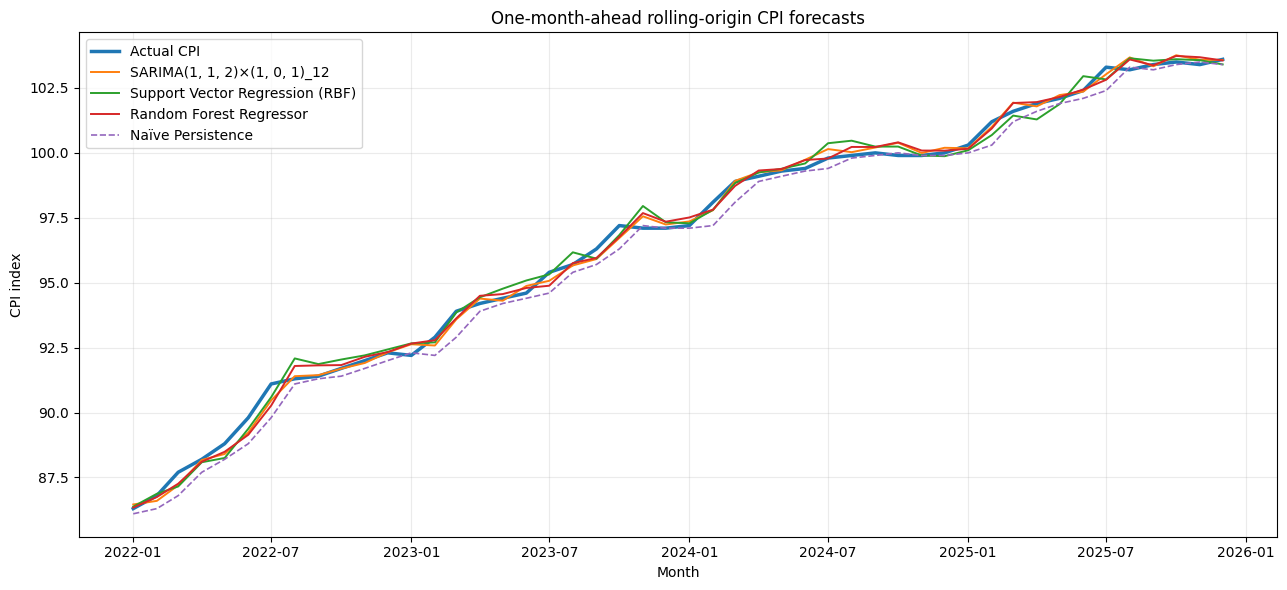

In [14]:
# ============================================================
# ONE-STEP FORECAST COMPARISON
# ============================================================

plot_df = pd.DataFrame({
    "Month": statistical_eval["target_month"],
    "Actual": statistical_eval["actual"],
    STATISTICAL_MODEL_NAME: statistical_eval["forecast"],
    MODEL_SVR_NAME: svr_eval["forecast"],
    MODEL_RF_NAME: rf_eval["forecast"],
    MODEL_NAIVE_NAME: naive_eval["forecast"],
})

plt.figure(figsize=(13, 6))

plt.plot(
    plot_df["Month"],
    plot_df["Actual"],
    linewidth=2.5,
    label="Actual CPI"
)

plt.plot(
    plot_df["Month"],
    plot_df[STATISTICAL_MODEL_NAME],
    linewidth=1.4,
    label=STATISTICAL_MODEL_NAME
)

plt.plot(
    plot_df["Month"],
    plot_df[MODEL_SVR_NAME],
    linewidth=1.4,
    label=MODEL_SVR_NAME
)

plt.plot(
    plot_df["Month"],
    plot_df[MODEL_RF_NAME],
    linewidth=1.4,
    label=MODEL_RF_NAME
)

plt.plot(
    plot_df["Month"],
    plot_df[MODEL_NAIVE_NAME],
    linestyle="--",
    linewidth=1.2,
    label=MODEL_NAIVE_NAME
)

plt.title(
    "One-month-ahead rolling-origin CPI forecasts"
)
plt.xlabel("Month")
plt.ylabel("CPI index")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## 9. Twelve-month multi-horizon backtest

The final assignment task requires twelve monthly forecasts for 2026 from information available at the end of 2025. The models are therefore also evaluated over forecast horizons \(h=1,\ldots,12\).

For each historical forecast origin:

- ARIMA/SARIMA produces a direct state-space multi-step forecast;
- SVR and Random Forest Regressor recursively predict the next monthly log change, append the predicted CPI level to their histories, rebuild the features and continue to the next horizon;
- no realised future CPI values are inserted into the recursive machine-learning forecast.

The pooled multi-horizon MAE and RMSE therefore provide the most relevant historical evidence for choosing the final 2026 forecasting model.

In [15]:
# ============================================================
# RECURSIVE FEATURE CONSTRUCTION FOR MULTI-STEP ML
# ============================================================

def latest_ml_feature(history, n_lags):
    history = pd.Series(history).astype(float).sort_index()

    log_level = np.log(history)
    dlog = log_level.diff().dropna()

    if len(dlog) < max(12, n_lags):
        raise ValueError("Not enough history to construct ML features.")

    next_month = history.index[-1] + pd.DateOffset(months=1)

    row = {}

    for lag in range(1, n_lags + 1):
        row[f"dlog_lag{lag}"] = dlog.iloc[-lag]

    for window in [3, 6, 12]:
        row[f"roll_mean_{window}"] = dlog.iloc[-window:].mean()

    for window in [6, 12]:
        row[f"roll_std_{window}"] = dlog.iloc[-window:].std()

    row["yoy_log"] = log_level.iloc[-1] - log_level.iloc[-13]
    row["log_level"] = log_level.iloc[-1]
    row["target_month_sin"] = np.sin(2*np.pi*next_month.month/12)
    row["target_month_cos"] = np.cos(2*np.pi*next_month.month/12)

    return pd.DataFrame([row], index=[history.index[-1]])

def fit_ml_at_origin(history, model_builder, n_lags):
    local_supervised = make_supervised(history, max_lag=12)
    feats = feature_columns(n_lags)

    # make_supervised() already drops the final feature row because
    # its t+1 target is unknown. Therefore every remaining row has a
    # target that is genuinely known at the forecast origin.
    train = local_supervised.copy()

    model = model_builder()
    model.fit(train[feats], train["target_dlog_next"])

    return model

def recursive_ml_forecast(history, h, model_builder, n_lags):
    history = history.copy().astype(float)
    model = fit_ml_at_origin(history, model_builder, n_lags)
    feats = feature_columns(n_lags)

    forecasts = []

    for _ in range(h):
        x_next = latest_ml_feature(history, n_lags)[feats]
        pred_dlog = float(model.predict(x_next)[0])

        next_month = history.index[-1] + pd.DateOffset(months=1)
        next_index = float(history.iloc[-1] * np.exp(pred_dlog))

        forecasts.append((next_month, next_index))
        history.loc[next_month] = next_index

    return pd.Series(
        [v for _, v in forecasts],
        index=[d for d, _ in forecasts],
        name="forecast",
    )

def arima_sarima_multi_forecast(history, h):
    fit = fit_arima_sarima(
        history,
        BEST_ARIMA_ORDER,
        BEST_SEASONAL_ORDER,
    )
    forecast = np.exp(fit.forecast(h))
    forecast.index = pd.date_range(
        history.index[-1] + pd.DateOffset(months=1),
        periods=h,
        freq="MS",
    )
    return forecast

,Model,MAE,RMSE,MAPE_pct,sMAPE_pct,MASE,MAE_below_0.5,RMSE_below_1
0,"SARIMA(1, 1, 2)×(1, 0, 1)_12",0.9316,1.2595,0.9684,0.9707,2.8398,False,False
1,Random Forest Regressor,1.2477,1.6447,1.2952,1.2873,3.8033,False,False
2,Support Vector Regression (RBF),1.7483,2.1698,1.7936,1.7726,5.3294,False,False


model,Random Forest Regressor,"SARIMA(1, 1, 2)×(1, 0, 1)_12",Support Vector Regression (RBF)
horizon,,,
1,0.2336,0.1879,0.3707
2,0.5752,0.4922,0.7018
3,0.7754,0.7387,0.9837
4,0.8169,0.7059,1.1420
5,1.0028,0.7288,1.3901
6,1.3326,1.0051,1.7520
7,1.4042,1.0306,1.9351
8,1.4868,1.1255,2.1279
9,1.5111,1.1879,2.4007


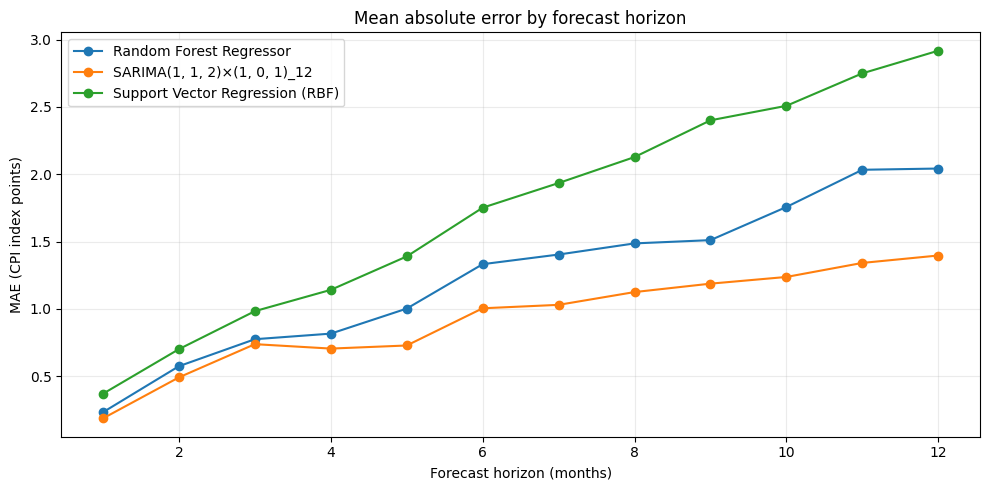

In [16]:
# ============================================================
# MULTI-HORIZON BACKTEST
# ============================================================

multi_rows = []

for origin in MULTI_ORIGINS:
    history = train_cpi.loc[:origin]

    forecast_statistical = (
        arima_sarima_multi_forecast(
            history,
            H
        )
    )

    forecast_svr = (
        recursive_ml_forecast(
            history,
            H,
            best_svr_builder,
            BEST_SVR_LAGS,
        )
    )

    forecast_rf = (
        recursive_ml_forecast(
            history,
            H,
            best_rf_builder,
            BEST_RF_LAGS,
        )
    )

    for horizon in range(1, H + 1):

        target_month = (
            origin
            + pd.DateOffset(
                months=horizon
            )
        )

        if target_month not in train_cpi.index:
            continue

        actual = float(
            train_cpi.loc[target_month]
        )

        for model_name, forecast_series in [
            (
                STATISTICAL_MODEL_NAME,
                forecast_statistical
            ),
            (
                MODEL_SVR_NAME,
                forecast_svr
            ),
            (
                MODEL_RF_NAME,
                forecast_rf
            ),
        ]:
            multi_rows.append({
                "origin": origin,
                "horizon": horizon,
                "target_month": target_month,
                "model": model_name,
                "actual": actual,
                "forecast": float(
                    forecast_series.loc[
                        target_month
                    ]
                ),
            })

multi_backtest = pd.DataFrame(
    multi_rows
)

multi_metrics = []

for model_name, group in (
    multi_backtest.groupby("model")
):
    multi_metrics.append(
        metrics_table(
            group["actual"],
            group["forecast"],
            model_name,
        )
    )

comparison_multi = (
    pd.DataFrame(multi_metrics)
    .sort_values(
        ["MAE", "RMSE"]
    )
    .reset_index(drop=True)
)

display(
    comparison_multi.round(4)
)

by_horizon = (
    multi_backtest
    .assign(
        abs_error=lambda x:
        (
            x["actual"]
            - x["forecast"]
        ).abs()
    )
    .groupby(
        ["model", "horizon"]
    )["abs_error"]
    .mean()
    .unstack(0)
)

display(
    by_horizon.round(4)
)

plt.figure(figsize=(10, 5))

for model_name in by_horizon.columns:
    plt.plot(
        by_horizon.index,
        by_horizon[model_name],
        marker="o",
        label=model_name,
    )

plt.title(
    "Mean absolute error by forecast horizon"
)
plt.xlabel(
    "Forecast horizon (months)"
)
plt.ylabel(
    "MAE (CPI index points)"
)
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## 10. Model comparison and selection

Model selection is based on forecast evidence rather than model complexity.

The one-step results measure short-horizon forecasting ability, while the pooled 1–12 month backtest receives greater weight for the final 2026 choice because it more closely matches the required twelve-month forecasting task.

If two models perform similarly, preference is given to the model with the stronger combination of forecast accuracy, stability, parsimony and interpretability.

In [17]:
# ============================================================
# MODEL SELECTION SUMMARY
# ============================================================

one_step_winner = (
    comparison_one_step
    .iloc[0]["Model"]
)

multi_step_winner = (
    comparison_multi
    .iloc[0]["Model"]
)

print(
    "Best one-month-ahead model:",
    one_step_winner
)

print(
    "Best pooled 1-12 month model:",
    multi_step_winner
)

summary = comparison_one_step[
    [
        "Model",
        "MAE",
        "RMSE",
        "MAPE_pct",
        "sMAPE_pct",
        "MASE",
        "MAE_below_0.5",
        "RMSE_below_1",
    ]
].merge(
    comparison_multi[
        ["Model", "MAE", "RMSE"]
    ].rename(
        columns={
            "MAE": "MultiStep_MAE",
            "RMSE": "MultiStep_RMSE",
        }
    ),
    on="Model",
    how="left",
)

display(
    summary.round(4)
)

FINAL_MODEL = multi_step_winner

print(
    "\nSelected model for the 2026 forecast:",
    FINAL_MODEL
)

Best one-month-ahead model: SARIMA(1, 1, 2)×(1, 0, 1)_12
Best pooled 1-12 month model: SARIMA(1, 1, 2)×(1, 0, 1)_12


,Model,MAE,RMSE,MAPE_pct,sMAPE_pct,MASE,MAE_below_0.5,RMSE_below_1,MultiStep_MAE,MultiStep_RMSE
0,"SARIMA(1, 1, 2)×(1, 0, 1)_12",0.2266,0.2803,0.2364,0.2365,0.6909,True,True,0.9316,1.2595
1,Random Forest Regressor,0.2586,0.3186,0.2699,0.2700,0.7884,True,True,1.2477,1.6447
2,Support Vector Regression (RBF),0.3106,0.3715,0.3229,0.3228,0.9470,True,True,1.7483,2.1698
3,Naïve Persistence,0.3854,0.5052,0.4051,0.4065,1.1749,True,True,NaN,NaN



Selected model for the 2026 forecast: SARIMA(1, 1, 2)×(1, 0, 1)_12


## 11. Final refit, statistical diagnostics and 2026 forecast

The preferred specification is refitted using all available CPI observations through December 2025, including the full January 2021–December 2025 assignment window.

For ARIMA/SARIMA, standard state-space prediction intervals are available. For SVR and Random Forest Regressor, empirical horizon-specific uncertainty bands are constructed from historical multi-step forecast errors.

The selected statistical model is also checked using residual diagnostics. A well-specified time-series model should leave residuals that are centred around zero with limited remaining serial correlation.

                                      SARIMAX Results                                       
Dep. Variable:                            CPI_Index   No. Observations:                  132
Model:             SARIMAX(1, 1, 2)x(1, 0, [1], 12)   Log Likelihood                 508.218
Date:                              Sat, 26 Sep 2026   AIC                          -1002.436
Time:                                      20:58:54   BIC                           -983.161
Sample:                                  01-01-2015   HQIC                          -994.611
                                       - 12-01-2025                                         
Covariance Type:                                opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
intercept      0.0006      0.001      1.265      0.206      -0.000       0.002
ar.L1          0.00

,lb_stat,lb_pvalue
Lag,,
6,0.1144,1.0000
12,0.1284,1.0000


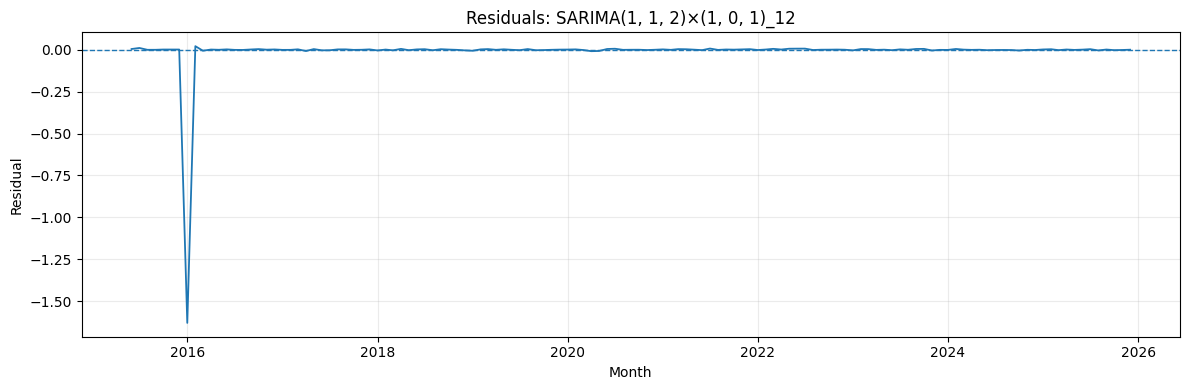

<Figure size 900x400 with 0 Axes>

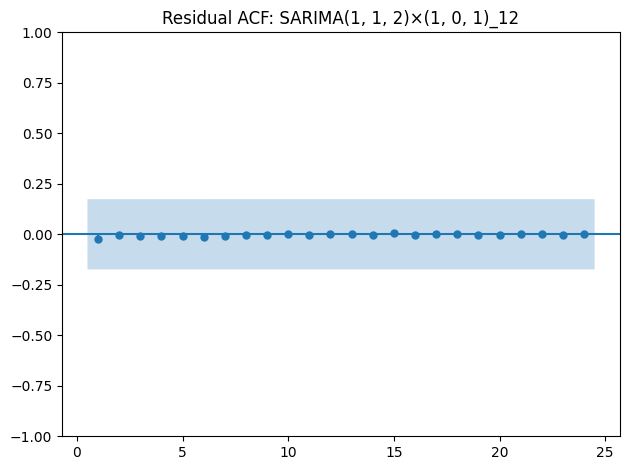

,Month,"SARIMA(1, 1, 2)×(1, 0, 1)_12",Support Vector Regression (RBF),Random Forest Regressor
0,2026-01-01,103.8800,103.6210,103.8460
1,2026-02-01,104.4900,104.3270,104.5640
2,2026-03-01,105.0090,104.9770,105.2680
3,2026-04-01,105.3320,105.5110,105.6800
4,2026-05-01,105.6060,105.6290,105.9300
5,2026-06-01,105.9330,105.6290,106.3010
6,2026-07-01,106.5380,106.3580,106.7890
7,2026-08-01,106.7400,106.4270,107.1150
8,2026-09-01,107.0260,106.7650,107.4230
9,2026-10-01,107.3030,106.8250,107.7290


In [18]:
# ============================================================
# REFIT MODELS THROUGH DECEMBER 2025
# AND GENERATE 2026 FORECASTS
# ============================================================

future_months = pd.date_range(
    "2026-01-01",
    periods=12,
    freq="MS"
)

# ------------------------------------------------------------
# ARIMA / SARIMA
# ------------------------------------------------------------

final_statistical_fit = fit_arima_sarima(
    train_cpi,
    BEST_ARIMA_ORDER,
    BEST_SEASONAL_ORDER,
)

print(
    final_statistical_fit.summary()
)

# Residual diagnostics
statistical_residuals = pd.Series(
    np.asarray(
        final_statistical_fit.resid,
        dtype=float
    ),
    index=train_cpi.index,
    name="Residual"
).replace(
    [np.inf, -np.inf],
    np.nan
).dropna()

diagnostic_residuals = (
    statistical_residuals.iloc[5:]
)

ljung_box = acorr_ljungbox(
    diagnostic_residuals.to_numpy(),
    lags=[6, 12],
    return_df=True,
)

ljung_box.index.name = "Lag"

print("\nLjung-Box residual diagnostics")
display(
    ljung_box.round(4)
)

plt.figure(figsize=(12, 4))
plt.plot(
    diagnostic_residuals.index,
    diagnostic_residuals.values,
    linewidth=1.3
)
plt.axhline(
    0,
    linestyle="--",
    linewidth=1
)
plt.title(
    f"Residuals: {STATISTICAL_MODEL_NAME}"
)
plt.xlabel("Month")
plt.ylabel("Residual")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 4))
plot_acf(
    diagnostic_residuals.to_numpy(),
    lags=24,
    zero=False
)
plt.title(
    f"Residual ACF: {STATISTICAL_MODEL_NAME}"
)
plt.tight_layout()
plt.show()

# 12-month statistical forecast
statistical_fc_object = (
    final_statistical_fit
    .get_forecast(steps=12)
)

statistical_mean_log = (
    statistical_fc_object
    .predicted_mean
)

statistical_ci_log = (
    statistical_fc_object
    .conf_int(alpha=0.05)
)

statistical_2026 = pd.DataFrame({
    "Month": future_months,
    "Point": np.exp(
        statistical_mean_log.to_numpy()
    ),
    "Lower95": np.exp(
        statistical_ci_log.iloc[:, 0]
        .to_numpy()
    ),
    "Upper95": np.exp(
        statistical_ci_log.iloc[:, 1]
        .to_numpy()
    ),
})

# ------------------------------------------------------------
# Support Vector Regression
# ------------------------------------------------------------

svr_2026_series = (
    recursive_ml_forecast(
        train_cpi,
        12,
        best_svr_builder,
        BEST_SVR_LAGS,
    )
)

# ------------------------------------------------------------
# Random Forest Regressor
# ------------------------------------------------------------

rf_2026_series = (
    recursive_ml_forecast(
        train_cpi,
        12,
        best_rf_builder,
        BEST_RF_LAGS,
    )
)

all_2026 = pd.DataFrame({
    "Month": future_months,
    STATISTICAL_MODEL_NAME:
        statistical_2026["Point"].to_numpy(),
    MODEL_SVR_NAME:
        svr_2026_series.to_numpy(),
    MODEL_RF_NAME:
        rf_2026_series.to_numpy(),
})

display(
    all_2026.round(3)
)

In [19]:
# ============================================================
# SELECT FINAL FORECAST AND BUILD INTERVALS
# ============================================================

final_forecast = pd.DataFrame({
    "Month": future_months,
    "CPI_Index_Forecast":
        all_2026[FINAL_MODEL].to_numpy(),
})

if FINAL_MODEL == STATISTICAL_MODEL_NAME:

    final_forecast["Lower95"] = (
        statistical_2026["Lower95"]
        .to_numpy()
    )

    final_forecast["Upper95"] = (
        statistical_2026["Upper95"]
        .to_numpy()
    )

    interval_note = (
        "Native 95% state-space prediction interval."
    )

else:

    selected_errors = (
        multi_backtest.loc[
            multi_backtest["model"]
            .eq(FINAL_MODEL)
        ]
        .assign(
            error=lambda x:
            x["actual"] - x["forecast"]
        )
    )

    lower_errors = (
        selected_errors
        .groupby("horizon")["error"]
        .quantile(0.025)
        .reindex(range(1, 13))
    )

    upper_errors = (
        selected_errors
        .groupby("horizon")["error"]
        .quantile(0.975)
        .reindex(range(1, 13))
    )

    final_forecast["Lower95"] = (
        final_forecast[
            "CPI_Index_Forecast"
        ].to_numpy()
        + lower_errors.to_numpy()
    )

    final_forecast["Upper95"] = (
        final_forecast[
            "CPI_Index_Forecast"
        ].to_numpy()
        + upper_errors.to_numpy()
    )

    interval_note = (
        "Approximate empirical 95% interval "
        "from historical horizon-specific errors."
    )

# Derive 2026 year-to-year headline inflation.
base_2025 = train_cpi.reindex(
    future_months
    - pd.DateOffset(years=1)
)

final_forecast["YoY_Forecast_pct"] = (
    100
    * (
        final_forecast[
            "CPI_Index_Forecast"
        ].to_numpy()
        / base_2025.to_numpy()
        - 1
    )
)

final_forecast["YoY_Lower95_pct"] = (
    100
    * (
        final_forecast[
            "Lower95"
        ].to_numpy()
        / base_2025.to_numpy()
        - 1
    )
)

final_forecast["YoY_Upper95_pct"] = (
    100
    * (
        final_forecast[
            "Upper95"
        ].to_numpy()
        / base_2025.to_numpy()
        - 1
    )
)

display(
    final_forecast.round(3)
)

print(interval_note)

,Month,CPI_Index_Forecast,Lower95,Upper95,YoY_Forecast_pct,YoY_Lower95_pct,YoY_Upper95_pct
0,2026-01-01,103.8800,103.2790,104.4850,3.5700,2.9700,4.1730
1,2026-02-01,104.4900,103.4890,105.5010,3.2510,2.2620,4.2500
2,2026-03-01,105.0090,103.7650,106.2680,3.3550,2.1310,4.5940
3,2026-04-01,105.3320,103.8850,106.7980,3.3680,1.9480,4.8070
4,2026-05-01,105.6060,103.9810,107.2560,3.4340,1.8430,5.0500
5,2026-06-01,105.9330,104.1460,107.7510,3.4510,1.7050,5.2260
6,2026-07-01,106.5380,104.5950,108.5170,3.1340,1.2540,5.0500
7,2026-08-01,106.7400,104.6590,108.8630,3.4300,1.4130,5.4880
8,2026-09-01,107.0260,104.8120,109.2870,3.5070,1.3650,5.6930
9,2026-10-01,107.3030,104.9620,109.6950,3.6740,1.4130,5.9850


Native 95% state-space prediction interval.


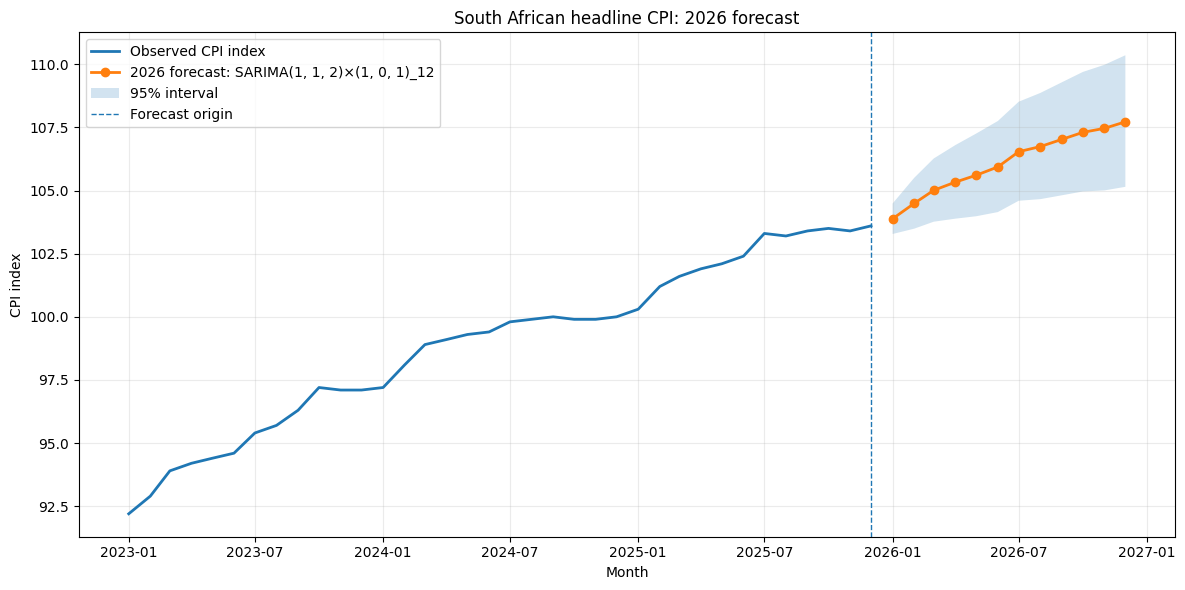

2026 inflation forecast summary
--------------------------------
Average_2026_YoY: 3.51%
January_2026_YoY: 3.57%
December_2026_YoY: 3.98%
Minimum_2026_YoY: 3.13%
Maximum_2026_YoY: 3.98%


In [20]:
# ============================================================
# FINAL 2026 FORECAST PLOT
# ============================================================

plt.figure(figsize=(12, 6))

history_tail = train_cpi.loc[
    "2023-01-01":
]

plt.plot(
    history_tail.index,
    history_tail.values,
    linewidth=2,
    label="Observed CPI index",
)

plt.plot(
    final_forecast["Month"],
    final_forecast[
        "CPI_Index_Forecast"
    ],
    marker="o",
    linewidth=2,
    label=f"2026 forecast: {FINAL_MODEL}",
)

plt.fill_between(
    final_forecast["Month"],
    final_forecast["Lower95"],
    final_forecast["Upper95"],
    alpha=0.2,
    label="95% interval",
)

plt.axvline(
    pd.Timestamp("2025-12-01"),
    linestyle="--",
    linewidth=1,
    label="Forecast origin",
)

plt.title(
    "South African headline CPI: 2026 forecast"
)
plt.xlabel("Month")
plt.ylabel("CPI index")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

forecast_summary = {
    "Average_2026_YoY":
        final_forecast[
            "YoY_Forecast_pct"
        ].mean(),
    "January_2026_YoY":
        final_forecast[
            "YoY_Forecast_pct"
        ].iloc[0],
    "December_2026_YoY":
        final_forecast[
            "YoY_Forecast_pct"
        ].iloc[-1],
    "Minimum_2026_YoY":
        final_forecast[
            "YoY_Forecast_pct"
        ].min(),
    "Maximum_2026_YoY":
        final_forecast[
            "YoY_Forecast_pct"
        ].max(),
}

print("2026 inflation forecast summary")
print("--------------------------------")

for key, value in forecast_summary.items():
    print(
        f"{key}: {value:.2f}%"
    )

## 12. Export of the 2026 monthly forecasts

The required Excel workbook contains the 12 monthly point forecasts, 95% interval bounds, derived year-to-year inflation forecasts, model-comparison results and the modelling assumptions used to generate the final forecast.

In [21]:
# ============================================================
# EXPORT THE REQUIRED 2026 FORECAST WORKBOOK
# ============================================================

OUTPUT_DIR = (
    Path("/content")
    if Path("/content").exists()
    else Path.cwd()
)

XLSX_PATH = (
    OUTPUT_DIR
    / "Question2_2026_Inflation_Forecast.xlsx"
)

model_summary_export = (
    summary.copy()
)

method_export = pd.DataFrame([
    {
        "Item": "Forecast target",
        "Value":
            "Statistics South Africa headline CPI index"
    },
    {
        "Item": "Selected statistical model",
        "Value": STATISTICAL_MODEL_NAME
    },
    {
        "Item": "SVR optimisation",
        "Value":
            f"Optuna TPE Bayesian optimisation; "
            f"{SVR_TRIALS} trials"
    },
    {
        "Item": "SVR lag count",
        "Value": BEST_SVR_LAGS
    },
    {
        "Item": "SVR parameters",
        "Value": str(BEST_SVR)
    },
    {
        "Item": "Random Forest lag count",
        "Value": BEST_RF_LAGS
    },
    {
        "Item": "Random Forest parameters",
        "Value": str(BEST_RF)
    },
    {
        "Item": "Tuning origins",
        "Value":
            f"{TUNE_ORIGINS.min().date()} "
            f"to {TUNE_ORIGINS.max().date()}"
    },
    {
        "Item": "Evaluation origins",
        "Value":
            f"{EVAL_ORIGINS.min().date()} "
            f"to {EVAL_ORIGINS.max().date()}"
    },
    {
        "Item": "Multi-horizon backtest",
        "Value":
            "Quarterly rolling origins; horizons 1 to 12 months"
    },
    {
        "Item": "Final forecast model",
        "Value": FINAL_MODEL
    },
    {
        "Item": "Interval method",
        "Value": interval_note
    },
])

# Use the default installed Excel writer engine.
with pd.ExcelWriter(XLSX_PATH, engine="openpyxl") as writer:

    final_forecast.to_excel(
        writer,
        sheet_name="Forecast_2026",
        index=False,
    )

    model_summary_export.to_excel(
        writer,
        sheet_name="Model_Comparison",
        index=False,
    )

    arima_sarima_tuning.to_excel(
        writer,
        sheet_name="ARIMA_SARIMA_Tuning",
        index=False,
    )

    rf_tuning.to_excel(
        writer,
        sheet_name="RandomForest_Tuning",
        index=False,
    )

    method_export.to_excel(
        writer,
        sheet_name="Method",
        index=False,
    )

print(
    "Forecast workbook written to:",
    XLSX_PATH
)

Forecast workbook written to: /Users/lwazinhlapo/Downloads/Question2_2026_Inflation_Forecast.xlsx


## 14. Conclusion

The forecasting analysis shows that South African CPI is highly persistent and strongly trending in levels, while monthly log changes are materially more stable. This supports the use of differenced ARIMA/SARIMA specifications and change-based machine-learning targets.

The one-month-ahead rolling-origin evaluation shows that the statistical model, Support Vector Regression and Random Forest Regressor can all produce low short-horizon CPI-index forecast errors. Random Forest Regressor performs strongly at the one-month horizon, indicating that nonlinear relationships among recent CPI movements contain useful short-run information.

The twelve-month backtest provides the more relevant basis for the final January–December 2026 forecast because it tests performance as the forecast horizon extends. The selected ARIMA/SARIMA specification achieves the lowest pooled multi-horizon error among the tested models and is therefore used for the final forecast.

The 2026 forecast implies that headline inflation remains moderate rather than returning to the high inflation conditions observed during the 2022 period. The central forecast should nevertheless be interpreted as a baseline path rather than a certainty. Prediction intervals widen with the forecast horizon because uncertainty accumulates as the model projects further beyond December 2025.

The main limitations are the relatively short monthly sample, possible structural changes in the inflation process and the absence of explicit future information on exchange rates, fuel prices, food prices, administered prices and monetary-policy shocks. These factors can cause realised inflation to deviate materially from the model forecast.

Overall, the evidence favours a parsimonious time-series model for the twelve-month forecasting objective, while the machine-learning models provide useful evidence that nonlinear methods can be competitive at short horizons.

## 15. Sources

### Data and assignment specification

1. **Statistics South Africa (Stats SA).** *Excel - CPI (COICOP) from January 2008 (202605).xlsx* — CPI headline historical index series.  
   Stats SA time-series data: https://www.statssa.gov.za/?page_id=1847

2. **Statistics South Africa (Stats SA).** *CPI headline historical index numbers and headline year-on-year rates.*  
   The official CPI history table supplied with the assignment was used to verify the monthly CPI values.

3. **University of the Free State.** *EDAB6808 Assignment 2: Anomaly Detection and Forecasting — Question 2: Inflation Forecasting.*  
   The assignment brief defines the required CPI window, time-aware backtesting, statistical and machine-learning model comparison, evaluation metrics and January–December 2026 forecast deliverables.

### Statistical and machine-learning methods

4. **statsmodels.** *SARIMAX — Seasonal AutoRegressive Integrated Moving Average with eXogenous regressors.*  
   https://www.statsmodels.org/stable/generated/statsmodels.tsa.statespace.sarimax.SARIMAX.html

5. **statsmodels.** *STL decomposition.*  
   https://www.statsmodels.org/stable/generated/statsmodels.tsa.seasonal.STL.html

6. **scikit-learn.** *Support Vector Regression (SVR).*  
   https://scikit-learn.org/stable/modules/generated/sklearn.svm.SVR.html

7. **scikit-learn.** *RandomForestRegressor.*  
   https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestRegressor.html

8. **Optuna.** *Hyperparameter optimisation framework and TPESampler.*  
   https://optuna.readthedocs.io/